In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "3"
import torch
from PIL import Image
from torchvision import transforms
from tqdm import tqdm
import shutil
root = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/mental_imagery_paper_b3/"
mindeye2_evals = "/home/naxos2-raid25/kneel027/home/kneel027/MindEye_Imagery/src/evals"

/export/raid1/home/kneel027/mamba/envs/SS/lib/python3.10/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: '/export/raid1/home/kneel027/mamba/envs/SS/lib/python3.10/site-packages/torchvision/image.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(


In [ ]:
for mode in ["imagery", "vision"]:
    for subject in [1,2,5,7]:
        model_name = f"mindeye1_subj0{subject}"
        all_recons = torch.zeros(18, 10, 3, 425, 425)
        all_blurryrecons = torch.zeros(18, 10, 3, 425, 425)
        all_clipvoxels = []
        for sample in tqdm(range(18)):
            for rep in range(10):
                image_path = f"{root}{mode}/mindeye/subject{subject}/{sample}/{rep}.png"
                image = Image.open(image_path)
                all_recons[sample, rep] = transforms.ToTensor()(image.resize((425, 425)))
                blurry_image_path = f"{root}{mode}/mindeye/subject{subject}/{sample}/low_level.png"
                blurry_image = Image.open(blurry_image_path)
                all_blurryrecons[sample, rep] = transforms.ToTensor()(blurry_image.resize((425, 425)))
            all_clipvoxels.append(torch.load(f"{root}{mode}/mindeye/subject{subject}/{sample}/clip_block.pt"))
        os.makedirs(f"{mindeye2_evals}/{model_name}", exist_ok=True)
        torch.save(all_recons, f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_{mode}.pt")
        
        torch.save(all_blurryrecons, f"{mindeye2_evals}/{model_name}/{model_name}_all_blurryrecons_{mode}.pt")
        torch.save(torch.stack(all_clipvoxels), f"{mindeye2_evals}/{model_name}/{model_name}_all_clipvoxels_{mode}.pt")

In [ ]:
for mode in ["imagery", "vision"]:
    for subject in [1,2,5,7]:
        model_name = f"braindiffuser_subj0{subject}"
        all_recons = torch.zeros(18, 10, 3, 425, 425)
        all_blurryrecons = torch.zeros(18, 10, 3, 425, 425)
        all_clipvoxels = []
        for sample in tqdm(range(18)):
            for rep in range(10):
                image_path = f"{root}{mode}/braindiffuser/subject{subject}/{sample}/{rep}.png"
                image = Image.open(image_path)
                all_recons[sample, rep] = transforms.ToTensor()(image.resize((425, 425)))
                blurry_image_path = f"{root}{mode}/braindiffuser/subject{subject}/{sample}/low_level.png"
                blurry_image = Image.open(blurry_image_path)
                all_blurryrecons[sample, rep] = transforms.ToTensor()(blurry_image.resize((425, 425)))
        os.makedirs(f"{mindeye2_evals}/{model_name}", exist_ok=True)
        torch.save(all_recons, f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_{mode}.pt")
        
        torch.save(all_blurryrecons, f"{mindeye2_evals}/{model_name}/{model_name}_all_blurryrecons_{mode}.pt")

In [ ]:
for mode in ["imagery", "vision"]:
    for subject in [1,2,5,7]:
        model_name = f"takagi_subj0{subject}"
        all_recons = torch.zeros(18, 10, 3, 425, 425)
        all_blurryrecons = torch.zeros(18, 10, 3, 425, 425)
        all_clipvoxels = []
        for sample in tqdm(range(18)):
            for rep in range(10):
                image_path = f"{root}{mode}/takagi/subject{subject}/{sample}/{rep}.png"
                image = Image.open(image_path)
                all_recons[sample, rep] = transforms.ToTensor()(image.resize((425, 425)))
                blurry_image_path = f"{root}{mode}/takagi/subject{subject}/{sample}/low_level.png"
                blurry_image = Image.open(blurry_image_path)
                all_blurryrecons[sample, rep] = transforms.ToTensor()(blurry_image.resize((425, 425)))
        os.makedirs(f"{mindeye2_evals}/{model_name}", exist_ok=True)
        torch.save(all_recons, f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_{mode}.pt")
        
        torch.save(all_blurryrecons, f"{mindeye2_evals}/{model_name}/{model_name}_all_blurryrecons_{mode}.pt")

In [47]:
for mode in ["vision", "imagery"]:
    for subject in [1]:
        for sessions, trials in zip([0.5, 1, 2, 3, 5, 10, 20, 40], [375, 750, 1500, 2250, 3750, 7500, 15000, 30000]):
            model_name = f"braindiffuser_subj0{subject}_{sessions}sess"
            raw_model_name = f"braindiffuser_{trials}"
            all_recons = torch.zeros(18, 10, 3, 1024, 1024)
            all_blurryrecons = torch.zeros(18, 3, 1024, 1024)
            all_clipvoxels = []
            for sample in tqdm(range(18)):
                blurry_image_path = f"{root}{mode}/{raw_model_name}/subject{subject}/{sample}/low_level.png"
                blurry_image = Image.open(blurry_image_path)
                all_blurryrecons[sample] = transforms.ToTensor()(blurry_image.resize((1024, 1024)))
                for rep in range(10):
                    image_path = f"{root}{mode}/{raw_model_name}/subject{subject}/{sample}/{rep}.png"
                    image = Image.open(image_path)
                    all_recons[sample, rep] = transforms.ToTensor()(image.resize((1024, 1024)))
                    
            os.makedirs(f"{mindeye2_evals}/{model_name}", exist_ok=True)
            torch.save(all_recons, f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_{mode}.pt")
            
            torch.save(all_blurryrecons, f"{mindeye2_evals}/{model_name}/{model_name}_all_blurryrecons_{mode}.pt")

100%|██████████| 18/18 [00:09<00:00,  1.84it/s]


In [3]:


for sessions, trials in zip([0.5, 1, 2, 3, 5, 10, 20, 40], [375, 750, 1500, 2250, 3750, 7500, 15000, 30000]):
    recons = torch.load(f"{mindeye2_evals}/brain_diffuser_{trials}_trials/subj01_brain_diffuser_{trials}_trials_all_recons.pt")
    torch.save(recons.unsqueeze(1), f"{mindeye2_evals}/braindiffuser_subj01_{sessions}sess/braindiffuser_subj01_{sessions}sess_all_recons_shared1000.pt")

/tmp/ipykernel_1694675/2337370507.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  recons = torch.load(f"{mindeye2_evals}/brain_diffuser_{trials}_trials/subj01_brain_diff

In [4]:
for mode in ["vision", "imagery"]:
    for subject in [1]:
        for sessions, trials in zip([0.5, 1, 2, 3, 5, 10, 20, 40], [375, 750, 1500, 2250, 3750, 7500, 15000, 30000]):
            model_name = f"takagi_subj0{subject}_{sessions}sess"
            raw_model_name = f"takagi_{trials}"
            all_recons = torch.zeros(18, 10, 3, 1024, 1024)
            all_blurryrecons = torch.zeros(18, 3, 1024, 1024)
            all_clipvoxels = []
            for sample in tqdm(range(18)):
                blurry_image_path = f"{root}{mode}/{raw_model_name}/subject{subject}/{sample}/low_level.png"
                blurry_image = Image.open(blurry_image_path)
                all_blurryrecons[sample] = transforms.ToTensor()(blurry_image.resize((1024, 1024)))
                for rep in range(10):
                    image_path = f"{root}{mode}/{raw_model_name}/subject{subject}/{sample}/{rep}.png"
                    image = Image.open(image_path)
                    all_recons[sample, rep] = transforms.ToTensor()(image.resize((1024, 1024)))
                    
            os.makedirs(f"{mindeye2_evals}/{model_name}", exist_ok=True)
            torch.save(all_recons, f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_{mode}.pt")
            
            torch.save(all_blurryrecons, f"{mindeye2_evals}/{model_name}/{model_name}_all_blurryrecons_{mode}.pt")

/tmp/ipykernel_3000407/2906885872.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  all_recons = torch.load(f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_{mode}.

In [ ]:
mode = "vision"
subject=1
model_name = f"iCNN_subj0{subject}_40sessions"
all_recons = torch.load(f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_{mode}.pt")

target_dim = 512
# Resize the images if necessary
if all_recons.shape[-1] != target_dim:
    all_recons_resized = torch.zeros((18, 10, 3, target_dim, target_dim))
    for sample in range(18):
        all_recons_resized[sample] = torch.nn.functional.interpolate(all_recons[sample], size=(target_dim, target_dim), mode='bilinear', antialias=False)
    all_recons = all_recons_resized

# # Normalize the tensor values to [0, 1] range
# all_recons = (all_recons - all_recons.min()) / (all_recons.max() - all_recons.min())

img = transforms.ToPILImage()(all_recons[7, 5])
print(torch.min(all_recons[6, 0]), torch.max(all_recons[6, 0]))
img

In [ ]:
root = "/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/reconstructions/"

for subject in [1, 2, 5, 7]:
    for mix_ratio in [0.4, 1.0, 0.0]:
        for mode in ["imagery", "vision"]:
            model_name = f"braindiffuser_subj0{subject}_{mix_ratio}_mix"
            all_recons = torch.zeros(18, 10, 3, 512, 512)
            all_blurryrecons = torch.zeros(18, 10, 3, 512, 512)
            all_clipvoxels = []
            for sample in tqdm(range(18)):
                for rep in range(10):
                    image_path = f"{root}{mode}/braindiffuser_augmentations/0.75-str_{mix_ratio}-mix/subject{subject}/{sample}/{rep}.png"
                    image = Image.open(image_path)
                    all_recons[sample, rep] = transforms.ToTensor()(image.resize((512, 512)))
                    blurry_image_path = f"{root}{mode}/braindiffuser_augmentations/0.75-str_{mix_ratio}-mix/subject{subject}/{sample}/low_level.png"
                    blurry_image = Image.open(image_path)
                    all_blurryrecons[sample, rep] = transforms.ToTensor()(blurry_image.resize((512, 512)))
            os.makedirs(f"{mindeye2_evals}/{model_name}", exist_ok=True)
            torch.save(all_recons, f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_{mode}.pt")
            
            torch.save(all_blurryrecons, f"{mindeye2_evals}/{model_name}/{model_name}_all_blurryrecons_{mode}.pt")

In [ ]:
for mode in ["vision", "imagery"]:
    blurry_recons = torch.load(f"{mindeye2_evals}/subj03_40sess_hypatia_ridge_scv_0.70_strength_100000_vwd_fs_fcon_short_captions/subj03_40sess_hypatia_ridge_scv_0.70_strength_100000_vwd_fs_fcon_short_captions_all_blurryrecons_{mode}.pt").reshape(18, 3, 768, 768)
    print(blurry_recons.shape)
    all_recons = torch.stack([blurry_recons]*10, dim=1)
    print(all_recons.shape)
    os.makedirs(f"{mindeye2_evals}/subj03_40sess_hypatia_ridge_scv_vdvae_only_nsd_general", exist_ok=True)
    torch.save(all_recons, f"{mindeye2_evals}/subj03_40sess_hypatia_ridge_scv_vdvae_only_nsd_general/subj03_40sess_hypatia_ridge_scv_vdvae_only_nsd_general_all_recons_{mode}.pt")


In [2]:
for mode in ["shared1000"]:
    for subject in [1, 2, 5, 7]:
        model_name = f"subj0{subject}_40sess_hypatia_mirage5"
        all_recons = torch.zeros(1000, 5, 3, 1024, 1024)
        all_blurryrecons = torch.zeros(1000, 3, 1024, 1024)
        all_clipvoxels = []
        for sample in tqdm(range(1000)):
            for rep in range(5):
                image_path = f"{root}{mode}/{model_name}/subject{subject}/{sample}/{rep}.png"
                image = Image.open(image_path)
                all_recons[sample, rep] = transforms.ToTensor()(image.resize((1024, 1024)))
                blurry_image_path = f"{root}{mode}/{model_name}/subject{subject}/{sample}/low_level.png"
                blurry_image = Image.open(blurry_image_path)
                all_blurryrecons[sample] = transforms.ToTensor()(blurry_image.resize((1024, 1024)))
        os.makedirs(f"{mindeye2_evals}/{model_name}", exist_ok=True)
        torch.save(all_recons, f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_{mode}.pt")
        
        torch.save(all_blurryrecons, f"{mindeye2_evals}/{model_name}/{model_name}_all_blurryrecons_{mode}.pt")

100%|██████████| 1000/1000 [15:29<00:00,  1.08it/s]


In [44]:
for mode in ["shared1000"]:
    for subject in [2, 5, 7]:
        path = f"/home/naxos2-raid25/kneel027/home/kneel027/MindEye_Imagery/src/evals/final_subj0{subject}_pretrained_40sess_24bs/"
        all_recons = torch.load(f"{path}/final_subj0{subject}_pretrained_40sess_24bs_all_recons_shared1000.pt").reshape(1000, 1, 3, 512, 512)
        torch.save(all_recons, f"{path}/final_subj0{subject}_pretrained_40sess_24bs_all_recons_shared1000.pt")
        

/tmp/ipykernel_2639296/1557273602.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  all_recons = torch.load(f"{path}/final_subj0{subject}_pretrained_40sess_24bs_all_recons

In [3]:
for subject in [1,2,5,7]:
    for mode in ["vision", "imagery"]:
        eval_path = f"{mindeye2_evals}/final_subj0{subject}_pretrained_40sess_24bs/"
        # shutil.copy(f"{eval_path}final_subj0{subject}_pretrained_40sess_24bs_all_recons_{mode}.pt", f"{eval_path}final_subj0{subject}_pretrained_40sess_24bs_all_enhancedrecons_{mode}.pt")
        all_enhancedrecons = torch.load(f"{eval_path}final_subj0{subject}_pretrained_40sess_24bs_all_enhancedrecons_{mode}.pt")
        all_blurryrecons = torch.load(f"{eval_path}final_subj0{subject}_pretrained_40sess_24bs_all_blurryrecons_{mode}.pt")
        all_recons = all_enhancedrecons * .75 + all_blurryrecons * .25
        torch.save(all_recons, f"{eval_path}final_subj0{subject}_pretrained_40sess_24bs_all_recons_{mode}.pt")

/tmp/ipykernel_3119859/2424354859.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  all_enhancedrecons = torch.load(f"{eval_path}final_subj0{subject}_pretrained_40sess_24b

In [7]:
for mode in ["imagery", "vision"]:
    for subject in [1,2,5,7]:
        for method in ["mindeye", "braindiffuser", "mindeye2"]:
            if mode == "imagery":
                num_reps = 16
            else:
                num_reps = 8
            for trial_reps in tqdm(range(1, num_reps+1)):
                save_name = f"{method}_subj0{subject}_{trial_reps}_trial_reps"
                all_recons = torch.zeros(18, 10, 3, 425, 425)
                for sample in range(18):
                    for rep in range(10):
                        image_path = f"{root}{mode}/{method}_{trial_reps}_trial_reps/subject{subject}/{sample}/{rep}.png"
                        image = Image.open(image_path)
                        all_recons[sample, rep] = transforms.ToTensor()(image.resize((425, 425)))
                os.makedirs(f"{mindeye2_evals}/{save_name}", exist_ok=True)
                torch.save(all_recons, f"{mindeye2_evals}/{save_name}/{save_name}_all_recons_{mode}.pt")

100%|██████████| 8/8 [01:11<00:00,  8.95s/it]


In [11]:
for mode in ["imagery", "vision"]:
    for subject in [1,2,5,7]:
        model_name = f"iCNN_subj0{subject}_40sessions"
        all_recons = torch.load(f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_{mode}.pt") / 255.0
        print(all_recons.shape)
        for sample in tqdm(range(18)):
            for rep in range(10):
                image_path = f"{root}{mode}/iCNN/subject{subject}/{sample}/"
                os.makedirs(image_path, exist_ok=True)
                image = transforms.ToPILImage()(all_recons[rep, sample]).resize((512, 512))
                image.save(f"{image_path}/{rep}.png")
                if rep==0:
                    image.save(f"{image_path}/low_level.png")

/tmp/ipykernel_1040251/3532792221.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  all_recons = torch.load(f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_{mode}.

torch.Size([10, 18, 3, 224, 224])


100%|██████████| 18/18 [00:26<00:00,  1.46s/it]


torch.Size([10, 18, 3, 224, 224])


100%|██████████| 18/18 [00:24<00:00,  1.36s/it]


...

100%|██████████| 18/18 [00:23<00:00,  1.28s/it]


torch.Size([10, 18, 3, 224, 224])


100%|██████████| 18/18 [00:23<00:00,  1.33s/it]


torch.Size([10, 18, 3, 224, 224])


100%|██████████| 18/18 [00:26<00:00,  1.48s/it]


In [4]:

for mode in ["shared1000"]:
    for subject in [1, 2, 5, 7]:
        model_name = f"mindeye1_subj0{subject}"
        all_recons = torch.zeros(1000, 1, 3, 512, 512)
        all_blurryrecons = torch.zeros(1000, 3, 512, 512)
        all_clipvoxels = []
        for sample in tqdm(range(1000)):
            for rep in range(1):
                image_path = f"{root}../mindeye_nsd_vision_40/subject{subject}/{sample}/{rep}.png"
                image = Image.open(image_path)
                all_recons[sample, rep] = transforms.ToTensor()(image.resize((512, 512)))
                blurry_image_path = f"{root}../mindeye_nsd_vision_40/subject{subject}/{sample}/low_level.png"
                blurry_image = Image.open(blurry_image_path)
                all_blurryrecons[sample] = transforms.ToTensor()(blurry_image.resize((512, 512)))
        os.makedirs(f"{mindeye2_evals}/{model_name}", exist_ok=True)
        torch.save(all_recons, f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_{mode}.pt")
        
        torch.save(all_blurryrecons, f"{mindeye2_evals}/{model_name}/{model_name}_all_blurryrecons_{mode}.pt")

100%|██████████| 1000/1000 [01:50<00:00,  9.07it/s]


/tmp/ipykernel_1170758/2280971810.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  recons = torch.load("/home/naxos2-raid25/kneel027/home/kneel027/MindEye_Imagery/src/eva

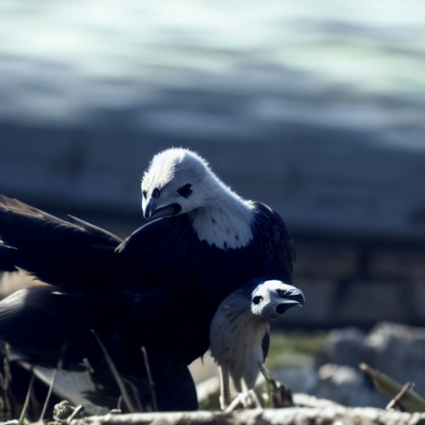

In [8]:
recons = torch.load("/home/naxos2-raid25/kneel027/home/kneel027/MindEye_Imagery/src/evals/mindeye_subj01_1_trial_reps/mindeye_subj01_1_trial_reps_all_recons_imagery.pt")
print
image = transforms.ToPILImage()(recons[6, 0])
image

In [3]:
root = "/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/reconstructions/"

for subject in [1, 2, 5, 7]:
    for strength in [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]:
        for mode in ["imagery", "vision"]:
            model_name = f"braindiffuser_jp_ts1_subj0{subject}_{strength}"
            all_recons = torch.zeros(18, 10, 3, 512, 512)
            for sample in tqdm(range(18)):
                for rep in range(10):
                    image_path = f"{root}{mode}/braindiffuser_augmentations/{strength}-str_1.0-mix/subject{subject}/{sample}/{rep}.png"
                    image = Image.open(image_path)
                    all_recons[sample, rep] = transforms.ToTensor()(image.resize((512, 512)))
            os.makedirs(f"{mindeye2_evals}/{model_name}", exist_ok=True)
            torch.save(all_recons, f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_{mode}.pt")

100%|██████████| 18/18 [00:05<00:00,  3.20it/s]


In [3]:
root = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/"

for s, subject in enumerate([1,2,5,7]):
    for version in ["2.3"]: #"2.1", "2.3" 
        for iteration in range(6):
            model_name=f"brain-optimized-inference_{version}_iter{iteration}_subj0{subject}"
            all_recons = torch.zeros(1000, 1, 3, 224, 224)
            for sample in tqdm(range(1000)):
                image_path = f"{root}brain-optimized-inference-v{version}/subject{subject}/{sample}/iter_{iteration}.png"
                image = Image.open(image_path)
                all_recons[sample, 0] = transforms.ToTensor()(image.resize((224, 224)))
            torch.save(all_recons, f"{root}/evals/{model_name}_all_recons.pt")
        
        model_name=f"brain-optimized-inference_{version}_basemodel_subj0{subject}"
        all_recons = torch.zeros(1000, 1, 3, 224, 224)
        for sample in tqdm(range(1000)):
            try:
                image_path = f"{root}brain-optimized-inference-v{version}/subject{subject}/{sample}/basemodel_recon.png"
                image = Image.open(image_path)
            except:
                image_path = f"{root}brain-optimized-inference-v{version}/subject{subject}/{sample}/MindEye.png"
                image = Image.open(image_path)
            all_recons[sample, 0] = transforms.ToTensor()(image.resize((224, 224)))
        torch.save(all_recons, f"{root}/evals/{model_name}_all_recons.pt")

        model_name=f"brain-optimized-inference_{version}_searchrecon_subj0{subject}"
        all_recons = torch.zeros(1000, 1, 3, 224, 224)
        for sample in tqdm(range(1000)):
            image_path = f"{root}brain-optimized-inference-v{version}/subject{subject}/{sample}/search_reconstruction.png"
            image = Image.open(image_path)
            all_recons[sample, 0] = transforms.ToTensor()(image.resize((224, 224)))
        torch.save(all_recons, f"{root}/evals/{model_name}_all_recons.pt")

100%|██████████| 1000/1000 [01:12<00:00, 13.86it/s]


In [ ]:
root = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/mental_imagery_paper_b3/"

for mode in ["imagery", "vision"]:
    for s, subject in enumerate([1,2,5,7]):
        for version in ["2.4"]: #"2.1", "2.3" 
            for iteration in range(6):
                model_name=f"brain-optimized-inference_{version}_iter{iteration}_subj0{subject}"
                all_recons = torch.zeros(1000, 1, 3, 224, 224)
                for sample in tqdm(range(1000)):
                    image_path = f"{root}brain-optimized-inference-v{version}/subject{subject}/{sample}/iter_{iteration}.png"
                    image = Image.open(image_path)
                    all_recons[sample, 0] = transforms.ToTensor()(image.resize((224, 224)))
                torch.save(all_recons, f"{root}/evals/{model_name}_all_recons.pt")
            
            model_name=f"brain-optimized-inference_{version}_basemodel_subj0{subject}"
            all_recons = torch.zeros(1000, 1, 3, 224, 224)
            for sample in tqdm(range(1000)):
                try:
                    image_path = f"{root}brain-optimized-inference-v{version}/subject{subject}/{sample}/basemodel_recon.png"
                    image = Image.open(image_path)
                except:
                    image_path = f"{root}brain-optimized-inference-v{version}/subject{subject}/{sample}/MindEye.png"
                    image = Image.open(image_path)
                all_recons[sample, 0] = transforms.ToTensor()(image.resize((224, 224)))
            torch.save(all_recons, f"{root}/evals/{model_name}_all_recons.pt")

            model_name=f"brain-optimized-inference_{version}_searchrecon_subj0{subject}"
            all_recons = torch.zeros(1000, 1, 3, 224, 224)
            for sample in tqdm(range(1000)):
                image_path = f"{root}brain-optimized-inference-v{version}/subject{subject}/{sample}/search_reconstruction.png"
                image = Image.open(image_path)
                all_recons[sample, 0] = transforms.ToTensor()(image.resize((224, 224)))
            torch.save(all_recons, f"{root}/evals/{model_name}_all_recons.pt")

In [6]:
root = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/"
for method in ["mindeye1"]: #"braindiffuser", 
    for topn in tqdm(range(1,64)):
        for objective in ["clip", "brain_corr"]:
            model_name=f"{method}_top{topn}_{objective}"
            all_recons = torch.load(f"{root}/{model_name}_all_recons.pt")
            for s, subject in enumerate([1,2,5,7]):
                subject_recons = all_recons[:, s]
                subject_recons = torch.nn.functional.interpolate(subject_recons, size=(224, 224), mode='bilinear', antialias=False).unsqueeze(1)
                torch.save(subject_recons, f"{root}/evals/{model_name}_subj0{subject}_all_recons.pt")
            os.remove(f"{root}/{model_name}_all_recons.pt")

  0%|          | 0/63 [00:00<?, ?it/s]/tmp/ipykernel_1377190/3457286538.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  all_recons = torch.load(f"{root}/{model_name}_all

In [8]:
root = "/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/reconstructions/"


for strength in [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]:
    model_name = f"braindiffuser_jp_ts1_gt_{strength}"
    all_recons = torch.zeros(18, 10, 3, 512, 512)
    for sample in tqdm(range(18)):
        for rep in range(10):
            image_path = f"{root}imagery/braindiffuser_augmentations/{strength}-str_1.0-mix_gt/subject1/{sample}/{rep}.png"
            image = Image.open(image_path)
            all_recons[sample, rep] = transforms.ToTensor()(image.resize((512, 512)))
    os.makedirs(f"{mindeye2_evals}/{model_name}", exist_ok=True)
    torch.save(all_recons, f"{mindeye2_evals}/{model_name}/{model_name}_all_recons_gt.pt")

  0%|          | 0/18 [00:00<?, ?it/s]

100%|██████████| 18/18 [00:06<00:00,  2.87it/s]


In [2]:
import os
import torch

import torch.nn.functional as F

destination_dir = '/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/evals'
os.makedirs(destination_dir, exist_ok=True)

for filename in tqdm(os.listdir(destination_dir)):
    if filename.endswith('.pt'):
        file_path = os.path.join(destination_dir, filename)
        tensor = torch.load(file_path)
        if tensor.ndim == 5 and tensor.shape[0] == 1000:
            resized_tensor = F.interpolate(tensor.view(-1, 3, tensor.shape[-2], tensor.shape[-1]),
                                          size=(224, 224), mode='bilinear', align_corners=False)
            resized_tensor = resized_tensor.view(1000, tensor.shape[1], 3, 224, 224)
            save_path = os.path.join(destination_dir, filename)
            torch.save(resized_tensor, save_path)

  0%|          | 0/1072 [00:00<?, ?it/s]/tmp/ipykernel_1362481/2492919512.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  tensor = torch.load(file_path)
100%|██████████

In [2]:
root = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/"
for mode in ['vision', 'imagery']:
    for s, subject in enumerate([1,2,5,7]):
        for version in ["2.1", "2.3", "2.4"]: # 
            for iteration in range(6):
                model_name=f"brain-optimized-inference_{version}_iter{iteration}_subj0{subject}"
                all_recons = torch.zeros(18, 1, 3, 224, 224)
                for sample in tqdm(range(18)):
                    image_path = f"{root}raw/{mode}/boi-v{version}/subject{subject}/{sample}/iter_{iteration}.png"
                    image = Image.open(image_path)
                    all_recons[sample, 0] = transforms.ToTensor()(image.resize((224, 224)))
                torch.save(all_recons, f"{root}/evals/{model_name}_all_recons_{mode}.pt")
            
            model_name=f"brain-optimized-inference_{version}_basemodel_subj0{subject}"
            all_recons = torch.zeros(18, 1, 3, 224, 224)
            for sample in tqdm(range(18)):
                try:
                    image_path = f"{root}raw/{mode}/boi-v{version}/subject{subject}/{sample}/basemodel_recon.png"
                    image = Image.open(image_path)
                except:
                    image_path = f"{root}raw/{mode}/boi-v{version}/subject{subject}/{sample}/MindEye.png"
                    image = Image.open(image_path)
                all_recons[sample, 0] = transforms.ToTensor()(image.resize((224, 224)))
            torch.save(all_recons, f"{root}/evals/{model_name}_all_recons_{mode}.pt")

            model_name=f"brain-optimized-inference_{version}_searchrecon_subj0{subject}"
            all_recons = torch.zeros(18, 1, 3, 224, 224)
            for sample in tqdm(range(18)):
                image_path = f"{root}raw/{mode}/boi-v{version}/subject{subject}/{sample}/search_reconstruction.png"
                image = Image.open(image_path)
                all_recons[sample, 0] = transforms.ToTensor()(image.resize((224, 224)))
            torch.save(all_recons, f"{root}/evals/{model_name}_all_recons_{mode}.pt")

100%|██████████| 18/18 [00:03<00:00,  5.74it/s]


In [3]:
root = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/mental_imagery_paper_b3/"
for mode in ['vision', 'imagery']:
    for s, subject in enumerate([1,2,5,7]):
        for version in ["2.1", "2.3", "2.4"]: # 
            for iteration in range(6):
                model_name=f"clip-optimized-inference_{version}_iter{iteration}_subj0{subject}"
                all_recons = torch.zeros(18, 1, 3, 224, 224)
                for sample in tqdm(range(18)):
                    image_path = f"{root}{mode}/coi-v{version}/subject{subject}/{sample}/iter_{iteration}/best_batch/0.png"
                    image = Image.open(image_path)
                    all_recons[sample, 0] = transforms.ToTensor()(image.resize((224, 224)))
                torch.save(all_recons, f"{root}/evals/{model_name}_all_recons_{mode}.pt")
            
            model_name=f"clip-optimized-inference_{version}_basemodel_subj0{subject}"
            all_recons = torch.zeros(18, 1, 3, 224, 224)
            for sample in tqdm(range(18)):
                try:
                    image_path = f"{root}{mode}/coi-v{version}/subject{subject}/{sample}/basemodel_recon.png"
                    image = Image.open(image_path)
                except:
                    image_path = f"{root}{mode}/coi-v{version}/subject{subject}/{sample}/MindEye.png"
                    image = Image.open(image_path)
                all_recons[sample, 0] = transforms.ToTensor()(image.resize((224, 224)))
            torch.save(all_recons, f"{root}/evals/{model_name}_all_recons_{mode}.pt")

            model_name=f"clip-optimized-inference_{version}_searchrecon_subj0{subject}"
            all_recons = torch.zeros(18, 1, 3, 224, 224)
            for sample in tqdm(range(18)):
                image_path = f"{root}{mode}/coi-v{version}/subject{subject}/{sample}/search_reconstruction.png"
                image = Image.open(image_path)
                all_recons[sample, 0] = transforms.ToTensor()(image.resize((224, 224)))
            torch.save(all_recons, f"{root}/evals/{model_name}_all_recons_{mode}.pt")

  0%|          | 0/18 [00:00<?, ?it/s]


FileNotFoundError: [Errno 2] No such file or directory: '/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/mental_imagery_paper_b3/vision/coi-v2.1/subject1/0/iter_0/best_batch/0.png'

In [9]:
for mode in ["imagery", "vision"]:
    for subject in [1,2,5,7]:
        for model_name in ["mindbridge"]:#, f"brainram", f"neuropictor"]:
            all_recons = torch.load(f"{mindeye2_evals}/{model_name}_subj0{subject}/{model_name}_subj0{subject}_all_recons_{mode}.pt")
            print(all_recons.shape)
            for sample in tqdm(range(18)):
                image_path = f"{root}{mode}/{model_name}/subject{subject}/{sample}/"
                os.makedirs(image_path, exist_ok=True)
                for rep in range(10):
                    image = transforms.ToPILImage()(all_recons[sample, rep]).resize((512, 512))
                    image.save(f"{image_path}/{rep}.png")
                image.save(f"{image_path}/low_level.png")
                gt_image = Image.open(f"{root}{mode}/mirage/subject{subject}/{sample}/ground_truth.png")
                gt_image.save(f"{image_path}/ground_truth.png")

/tmp/ipykernel_1718827/2682604951.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  all_recons = torch.load(f"{mindeye2_evals}/{model_name}_subj0{subject}/{model_name}_sub

torch.Size([18, 10, 3, 512, 512])


100%|██████████| 18/18 [00:18<00:00,  1.04s/it]


torch.Size([18, 10, 3, 512, 512])


100%|██████████| 18/18 [00:18<00:00,  1.04s/it]


...

100%|██████████| 18/18 [00:22<00:00,  1.23s/it]


torch.Size([18, 10, 3, 512, 512])


100%|██████████| 18/18 [00:21<00:00,  1.17s/it]


torch.Size([18, 10, 3, 512, 512])


100%|██████████| 18/18 [00:21<00:00,  1.18s/it]
